# Project Q: 6-Node Max-Cut QAOA Benchmark
### Evaluating Routing Overhead and Noise Sensitivity across Custom Processor Topologies

This notebook provides an end-to-end reproducible workflow for:
1. **Problem Formulation**: 6-node Erdős–Rényi graph ($n=6, p=0.5, \text{seed}=42$) with integer edge weights $\in [1, 5]$.
2. **Classical Baseline**: Exact brute-force solver finding the baseline Max-Cut value ($C_{\text{max}} = 16.0$).
3. **Quantum Formulation**: Anchoring Node 0 to state '0' to reduce the problem to exactly 5 quantum variables ($N=5$).
4. **Processor Topologies**:
   - **Processor A**: 5-qubit linear chain `[(0,1), (1,2), (2,3), (3,4)]`
   - **Processor B**: 9-qubit heavy-hex-inspired `[(0,1), (1,2), (1,6), (2,3), (2,6), (2,5), (3,4), (4,5), (5,6), (6,7), (6,8), (8,0)]`
   - **Noise Model**: 0.1% 1Q depolarizing, 0.5% 2Q CX depolarizing, 1.0% readout error.
5. **QAOA Routing & Transpilation**: Building $p=1$ QAOA circuits and compiling with `optimization_level=1, seed_transpiler=42`.
6. **Execution & Metrics**: 4096-shot noisy simulations, metric extraction (Depth, CX Count, SWAP Count, Approximation Ratio), and export to `results/tables/metrics.csv` and `results/figures/`.

In [1]:
# Cell 1: Imports and Environment Setup
import os
import sys

# Ensure src is in Python path
sys.path.insert(0, os.path.abspath('.'))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from qiskit import QuantumCircuit

from src.problem import (
    generate_graph,
    construct_cost_hamiltonian,
    solve_maxcut_brute_force,
    compute_cut_value,
)
from src.processors import (
    get_processor_a,
    get_processor_b,
    configure_both_processors,
)
from src.routing import build_qaoa_circuit, transpile_qaoa_circuit
from src.metrics import extract_routing_metrics, execute_and_evaluate
from src.visualization import (
    draw_problem_graph,
    draw_processor_coupling_maps,
    plot_metric_comparison,
)

print('All modules successfully imported!')

All modules successfully imported!


## 1. Problem Formulation & Exact Classical Baseline

We generate a 6-node Erdős–Rényi random graph ($p=0.5, \text{seed}=42$) and assign random integer edge weights between 1 and 5.
Then we solve for the exact maximum cut value using the classical brute-force solver.

Graph nodes: [0, 1, 2, 3, 4, 5]
Graph edges with weights: [(0, 2, {'weight': 1}), (0, 3, {'weight': 1}), (0, 4, {'weight': 3}), (1, 4, {'weight': 2}), (1, 5, {'weight': 2}), (2, 3, {'weight': 2}), (2, 4, {'weight': 1}), (3, 4, {'weight': 5}), (3, 5, {'weight': 1})]

EXACT MAX-CUT BASELINE: 16.0
Optimal Partition: {0: 0, 1: 0, 2: 1, 3: 0, 4: 1, 5: 1}
Optimal Bitstring (Node 0 to 5): 001011


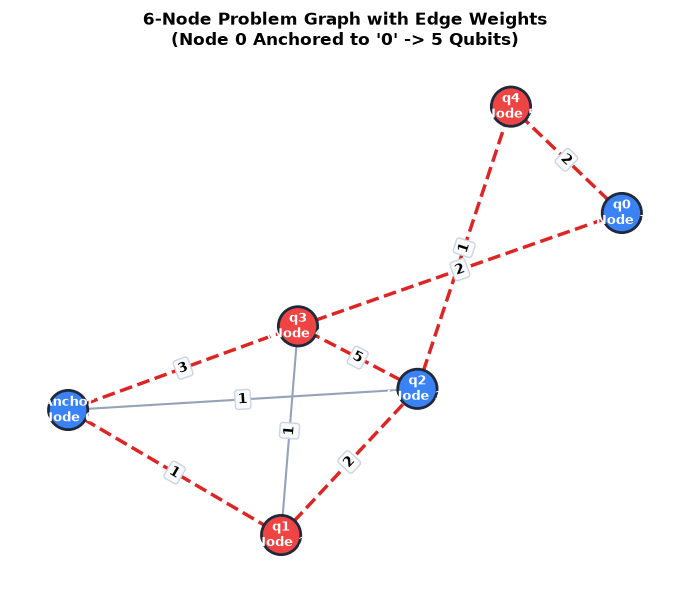

In [2]:
# Cell 2: Graph Generation and Classical Brute-Force Solve
G = generate_graph(n=6, p=0.5, seed=42, weight_seed=42)
print(f'Graph nodes: {list(G.nodes())}')
print(f'Graph edges with weights: {list(G.edges(data=True))}')

# Exact brute-force solver
baseline_res = solve_maxcut_brute_force(G)
max_cut_baseline = float(baseline_res)
best_partition = baseline_res.best_partition
best_bitstring = baseline_res.best_bitstring

print('\n' + '=' * 50)
print(f'EXACT MAX-CUT BASELINE: {max_cut_baseline}')
print(f'Optimal Partition: {best_partition}')
print(f'Optimal Bitstring (Node 0 to 5): {best_bitstring}')
print('=' * 50)

# Visualize and save problem graph
fig_graph, ax_graph = draw_problem_graph(G, partition=best_partition, save_path='results/figures/problem_graph.png')
plt.show()

## 2. Quantum Cost Hamiltonian Construction (Anchoring Node 0)

Max-Cut has global $\mathbb{Z}_2$ spin-flip symmetry ($x \leftrightarrow 1 - x$).
By anchoring **Node 0** to state '0' ($s_0 = +1$), we eliminate the symmetry and reduce the problem from 6 variables to exactly 5 quantum variables ($q_0 \dots q_4$), allowing it to fit directly on a 5-qubit processor.

In [3]:
# Cell 3: Construct Cost Hamiltonian
cost_hamiltonian, offset = construct_cost_hamiltonian(
    G, anchor_node=0, anchor_state=0, return_offset=True
)

print(f'Number of qubits: {cost_hamiltonian.num_qubits}')
print(f'Number of Pauli terms: {len(cost_hamiltonian)}')
print(f'Constant energy offset: {offset}')
print('\nHamiltonian Pauli terms:')
for pauli, coeff in cost_hamiltonian.to_list():
    print(f'  {pauli} : {coeff.real:+.2f}')

# Verify ground state energy matches -MaxCut
H_full = construct_cost_hamiltonian(G, anchor_node=0, anchor_state=0, include_offset=True)
eigvals = np.linalg.eigvalsh(H_full.to_matrix())
ground_energy = min(eigvals)
print(f'\nGround State Energy: {ground_energy:.4f}')
print(f'Verified: Ground State Energy equals -MaxCut? {np.isclose(ground_energy, -max_cut_baseline)}')

Number of qubits: 5
Number of Pauli terms: 9
Constant energy offset: -9.0

Hamiltonian Pauli terms:
  IIIZI : +0.50
  IIZII : +0.50
  IZIII : +1.50
  IZIIZ : +1.00
  ZIIIZ : +1.00
  IIZZI : +1.00
  IZIZI : +0.50
  IZZII : +2.50
  ZIZII : +0.50

Ground State Energy: -16.0000
Verified: Ground State Energy equals -MaxCut? True


## 3. Hardware Processor Models & Synthetic Noise

We configure:
- **Processor A**: 5 qubits, linear chain coupling map `[(0,1), (1,2), (2,3), (3,4)]`
- **Processor B**: 9 qubits, heavy-hex-inspired coupling map `[(0,1), (1,2), (1,6), (2,3), (2,6), (2,5), (3,4), (4,5), (5,6), (6,7), (6,8), (8,0)]`
- **Synthetic Noise Model**: 0.1% 1Q depolarizing, 0.5% 2Q CX depolarizing, 1.0% readout error.

Processor A: 5 qubits, basis: ['rz', 'sx', 'x', 'cx', 'break_loop', 'continue_loop', 'delay', 'for_loop', 'if_else', 'initialize', 'kraus', 'qerror_loc', 'quantum_channel', 'reset', 'roerror', 'save_amplitudes', 'save_amplitudes_sq', 'save_clifford', 'save_density_matrix', 'save_expval', 'save_expval_var', 'save_matrix_product_state', 'save_probabilities', 'save_probabilities_dict', 'save_stabilizer', 'save_state', 'save_statevector', 'save_statevector_dict', 'save_superop', 'save_unitary', 'set_density_matrix', 'set_matrix_product_state', 'set_stabilizer', 'set_statevector', 'set_superop', 'set_unitary', 'superop', 'switch_case', 'while_loop']
Processor B: 9 qubits, basis: ['rz', 'sx', 'x', 'cx', 'break_loop', 'continue_loop', 'delay', 'for_loop', 'if_else', 'initialize', 'kraus', 'qerror_loc', 'quantum_channel', 'reset', 'roerror', 'save_amplitudes', 'save_amplitudes_sq', 'save_clifford', 'save_density_matrix', 'save_expval', 'save_expval_var', 'save_matrix_product_state', 'save_prob

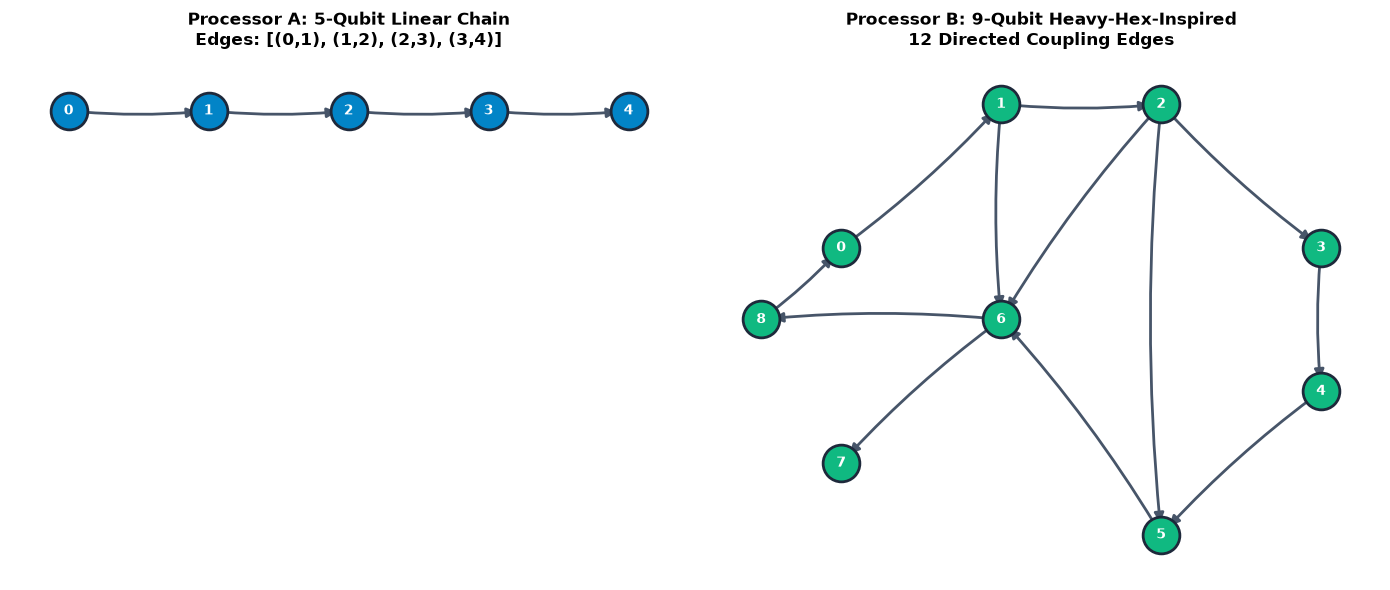

In [4]:
# Cell 4: Initialize Processors and Visualize Coupling Maps
proc_a, proc_b = configure_both_processors()

print(f'Processor A: {proc_a.num_qubits} qubits, basis: {proc_a.configuration().basis_gates}')
print(f'Processor B: {proc_b.num_qubits} qubits, basis: {proc_b.configuration().basis_gates}')

# Visualize and save coupling maps
fig_maps, axs_maps = draw_processor_coupling_maps(save_path='results/figures/coupling_maps.png')
plt.show()

## 4. QAOA Circuit Construction ($p=1$) & Transpilation

We construct the QAOA ansatz circuit for $p=1$ with parameters $\gamma = 0.3$ and $\beta = 1.2$, then transpile to both backends with `optimization_level=1` and `seed_transpiler=42`.

In [5]:
# Cell 5: Build QAOA Circuit and Transpile
qaoa_circuit = build_qaoa_circuit(
    cost_hamiltonian, p=1, gamma=0.3, beta=1.2, insert_measurements=True
)
print('Unrouted QAOA Circuit Summary:')
print(f'  Qubits: {qaoa_circuit.num_qubits}')
print(f'  Operations: {dict(qaoa_circuit.count_ops())}')
print(f'  Depth: {qaoa_circuit.depth()}')

# Transpile to Processor A
transpiled_a = transpile_qaoa_circuit(
    qaoa_circuit, proc_a, optimization_level=1, seed_transpiler=42
)

# Transpile to Processor B
transpiled_b = transpile_qaoa_circuit(
    qaoa_circuit, proc_b, optimization_level=1, seed_transpiler=42
)

# Extract routing metrics
metrics_a = extract_routing_metrics(transpiled_a)
metrics_b = extract_routing_metrics(transpiled_b)

print('\nRouting Metrics:')
print(f"  Processor A (5Q Linear):    Depth={metrics_a['depth']}, CX={metrics_a['cx_count']}, SWAPs={metrics_a['swap_count']}")
print(f"  Processor B (9Q Heavy-Hex): Depth={metrics_b['depth']}, CX={metrics_b['cx_count']}, SWAPs={metrics_b['swap_count']}")

Unrouted QAOA Circuit Summary:
  Qubits: 5
  Operations: {'cx': 12, 'rz': 9, 'h': 5, 'rx': 5, 'measure': 5, 'barrier': 1}
  Depth: 16

Routing Metrics:
  Processor A (5Q Linear):    Depth=60, CX=18, SWAPs=2
  Processor B (9Q Heavy-Hex): Depth=35, CX=12, SWAPs=0


## 5. Noisy Execution & Benchmark Evaluation (4096 Shots)

We execute the transpiled circuits on both noisy backends using 4096 shots, decode the measured partitions, compute the expected cut value $\langle C \rangle$, and calculate the approximation ratio $r = \langle C \rangle / C_{\text{max}}$.

In [6]:
# Cell 6: Execute and Evaluate on Noisy Backends
exec_res_a = execute_and_evaluate(transpiled_a, proc_a, graph=G, shots=4096, seed_simulator=42)
exec_res_b = execute_and_evaluate(transpiled_b, proc_b, graph=G, shots=4096, seed_simulator=42)

print('=' * 60)
print(f'Processor A Execution (Linear Chain):')
print(f'  Expected Cut:        {exec_res_a.expected_cut:.4f} / {max_cut_baseline}')
print(f'  Approximation Ratio: {exec_res_a.approximation_ratio:.4%}')
print(f'  Best Sampled Cut:    {exec_res_a.best_cut_observed}')

print(f'\nProcessor B Execution (Heavy-Hex):')
print(f'  Expected Cut:        {exec_res_b.expected_cut:.4f} / {max_cut_baseline}')
print(f'  Approximation Ratio: {exec_res_b.approximation_ratio:.4%}')
print(f'  Best Sampled Cut:    {exec_res_b.best_cut_observed}')
print('=' * 60)

Processor A Execution (Linear Chain):
  Expected Cut:        10.8625 / 16.0
  Approximation Ratio: 67.8909%
  Best Sampled Cut:    16.0

Processor B Execution (Heavy-Hex):
  Expected Cut:        11.0037 / 16.0
  Approximation Ratio: 68.7729%
  Best Sampled Cut:    16.0


## 6. Comparative Benchmark Metrics & Export

We compile the comparative benchmark metrics into a `pandas.DataFrame`, export it to `results/tables/metrics.csv`, and visualize the routing overhead using a grouped bar chart saved to `results/figures/metric_comparison.png`.

Benchmark metrics table exported successfully to results/tables/metrics.csv!

                    Processor A (5Q Linear) Processor B (9Q Heavy-Hex)
Circuit Depth                            60                         35
Total CX Count                           18                         12
SWAP Gate Count                           2                          0
Routing CX Overhead                       6                          0
Expected Cut                        10.8625                    11.0037
Max-Cut Baseline                       16.0                       16.0
Approximation Ratio                67.8909%                   68.7729%


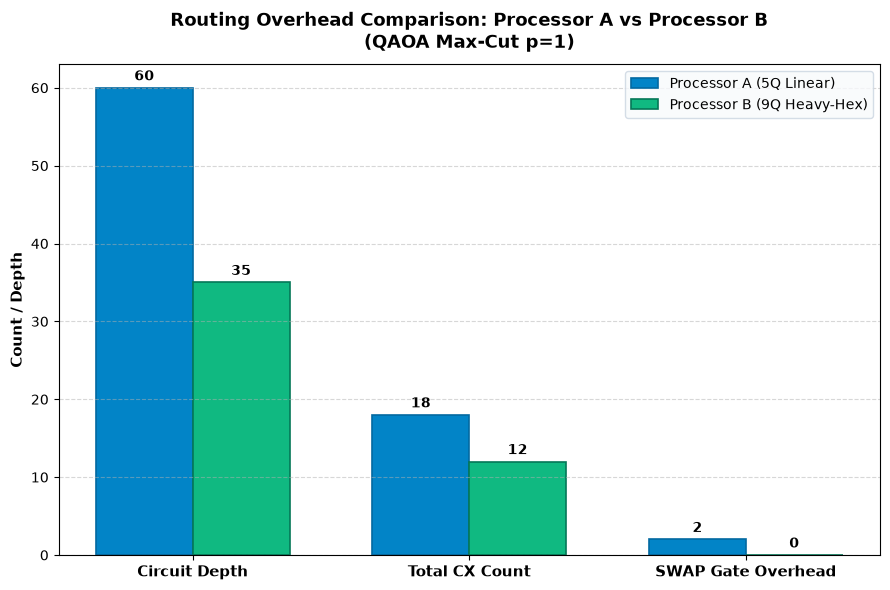

In [7]:
# Cell 7: Compile DataFrame, Export Table, and Plot Comparison
metrics_df = pd.DataFrame(
    {
        'Processor A (5Q Linear)': [
            metrics_a['depth'],
            metrics_a['cx_count'],
            metrics_a['swap_count'],
            metrics_a['routing_overhead_cx'],
            f"{exec_res_a.expected_cut:.4f}",
            max_cut_baseline,
            f"{exec_res_a.approximation_ratio:.4%}",
        ],
        'Processor B (9Q Heavy-Hex)': [
            metrics_b['depth'],
            metrics_b['cx_count'],
            metrics_b['swap_count'],
            metrics_b['routing_overhead_cx'],
            f"{exec_res_b.expected_cut:.4f}",
            max_cut_baseline,
            f"{exec_res_b.approximation_ratio:.4%}",
        ],
    },
    index=[
        'Circuit Depth',
        'Total CX Count',
        'SWAP Gate Count',
        'Routing CX Overhead',
        'Expected Cut',
        'Max-Cut Baseline',
        'Approximation Ratio',
    ],
)

# Export to CSV
os.makedirs('results/tables', exist_ok=True)
csv_path = 'results/tables/metrics.csv'
metrics_df.to_csv(csv_path)
print(f'Benchmark metrics table exported successfully to {csv_path}!\n')

# Display formatted table
print(metrics_df)

# Generate and save grouped bar chart
fig_comp, ax_comp = plot_metric_comparison(
    metrics_df, save_path='results/figures/metric_comparison.png'
)
plt.show()